In [1]:
# Behzad Ghabaei
# CS 82A - Data Science
# module8_lab2.ipynb
# lifecyclesavings.csv
# Textbook Problem 9.1, AI-Assisted
# Instructor Seno
# 10/15/2026


## Step 1: load the lifecyclesavings.csv file, look at the columns and data.
#### By hand (no AI): load the savings data, record shape and missing counts, and compute the mean of each column

loading csv file

In [2]:
from google.colab import files
files.upload()

import pandas as pd
df = pd.read_csv("lifecyclesavings.csv")

Saving lifecyclesavings.csv to lifecyclesavings.csv


getting the shape and also using useful tools like
df.info()
df.describe()
df.head()
df.dtypes
df.columns

In [3]:
df.shape

(50, 6)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Contry  50 non-null     object 
 1   sr      50 non-null     float64
 2   pop15   50 non-null     float64
 3   pop75   50 non-null     float64
 4   dpi     50 non-null     float64
 5   ddpi    50 non-null     float64
dtypes: float64(5), object(1)
memory usage: 2.5+ KB


In [5]:
df.describe()

,sr,pop15,pop75,dpi,ddpi
count,50.000000,50.000000,50.000000,50.000000,50.000000
mean,9.671000,35.089600,2.293000,1106.758400,3.757600
std,4.480407,9.151727,1.290771,990.868889,2.869871
min,0.600000,21.440000,0.560000,88.940000,0.220000
25%,6.970000,26.215000,1.125000,288.207500,2.002500
50%,10.510000,32.575000,2.175000,695.665000,3.000000
75%,12.617500,44.065000,3.325000,1795.622500,4.477500
max,21.100000,47.640000,4.700000,4001.890000,16.710000


In [6]:
df.head()

,Contry,sr,pop15,pop75,dpi,ddpi
0,Australia,11.43,29.35,2.87,2329.68,2.87
1,Austria,12.07,23.32,4.41,1507.99,3.93
2,Belgium,13.17,23.80,4.43,2108.47,3.82
3,Bolivia,5.75,41.89,1.67,189.13,0.22
4,Brazil,12.88,42.19,0.83,728.47,4.56


In [7]:
df.dtypes

,0
Contry,object
sr,float64
pop15,float64
pop75,float64
dpi,float64
ddpi,float64


In [8]:
df.columns

Index(['Contry', 'sr', 'pop15', 'pop75', 'dpi', 'ddpi'], dtype='object')

Now find the missings counts.

In [9]:
df.isnull().sum()

,0
Contry,0
sr,0
pop15,0
pop75,0
dpi,0
ddpi,0


long output but helpful to look at with value_counts()

In [10]:
print("Countries :\n")
print(df["Contry"].value_counts())

Countries :

Contry
Australia         1
Austria           1
Belgium           1
Bolivia           1
Brazil            1
Canada            1
Chile             1
China             1
Colombia          1
Costa Rica        1
Denmark           1
Ecuador           1
Finland           1
France            1
Germany           1
Greece            1
Guatamala         1
Honduras          1
Iceland           1
India             1
Ireland           1
Italy             1
Japan             1
Korea             1
Luxembourg        1
Malta             1
Norway            1
Netherlands       1
New Zealand       1
Nicaragua         1
Panama            1
Paraguay          1
Peru              1
Philippines       1
Portugal          1
South Africa      1
South Rhodesia    1
Spain             1
Sweden            1
Switzerland       1
Turkey            1
Tunisia           1
United Kingdom    1
United States     1
Venezuela         1
Zambia            1
Jamaica           1
Uruguay           1
Libya             1


Use groupby function with each combination to see what averages it yields.

In [11]:
print("Sr: numeric, aggregate personal savings")
print(df.groupby("Contry")["sr"].mean())
print("***"*8)
print("pop15: numeric percent of population under 15 years old")
print(df.groupby("Contry")["pop15"].mean())
print("***"*8)
print("pop75 (% Population over 75 years old)")
print(df.groupby("Contry")["pop75"].mean())
print("***"*8)
print("dpi: numeric resl per capita disposable income.")
print(df.groupby("Contry")["dpi"].mean())
print("***"*8)
print("ddpi: numeric percent growth rate of dpi.")
print(df.groupby("Contry")["ddpi"].mean())


Sr: numeric, aggregate personal savings
Contry
Australia         11.43
Austria           12.07
Belgium           13.17
Bolivia            5.75
Brazil            12.88
Canada             8.79
Chile              0.60
China             11.90
Colombia           4.98
Costa Rica        10.78
Denmark           16.85
Ecuador            3.59
Finland           11.24
France            12.64
Germany           12.55
Greece            10.67
Guatamala          3.01
Honduras           7.70
Iceland            1.27
India              9.00
Ireland           11.34
Italy             14.28
Jamaica            7.72
Japan             21.10
Korea              3.98
Libya              8.89
Luxembourg        10.35
Malaysia           4.71
Malta             15.48
Netherlands       14.65
New Zealand       10.67
Nicaragua          7.30
Norway            10.25
Panama             4.44
Paraguay           2.02
Peru              12.70
Philippines       12.78
Portugal          12.49
South Africa      11.14
South Rhodesia   

- aggregate personal savings: **Japan** has the highest average.
- numeric percent of population under 15 years old: **Honduras** at 47.32
- pop75 (% Population over 75 years old): **France** at 4.7
- dpi: numeric resl per capita disposable income.: **U.S.** at 4001.89
- ddpi: numeric percent growth rate of dpi.: **Libya** 16.71

Short Reflection: This problem describes the life cycle savings hypothesis developed by Franco Modigliani, the national savings ratio (aggregate personal savings divided by disposable income) and is explained per capita disposable income, the percentage rate of change in per capita disposable income, and two demographic variables: the percentage of the population less than 15 years old and the percentage of the population over 75 years old. The data are averaged over the decade 1960-1970 to remove the business cycle of other short term fluctuations.

- Sr: numeric, aggregate personal savings.
- pop15: numeric percent of population under 15.
- pop75: numeric percent of population over 75.
- dpi: numeric resl per capita disposable income.
- ddpi: numeric percent growth rate of dpi.



Lets try a dendrogram from the code snippets in chapter 9.

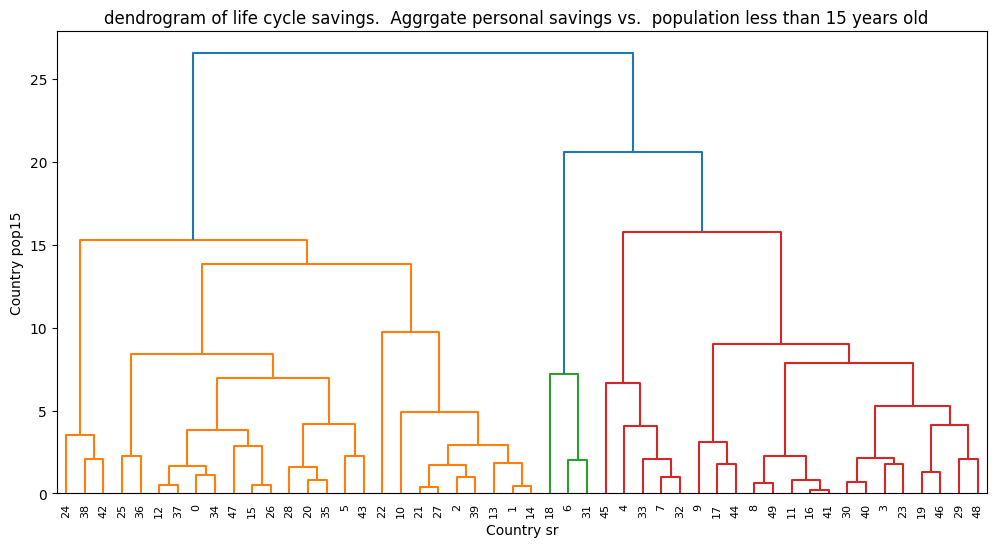

<function matplotlib.pyplot.show(close=None, block=None)>

In [12]:
import pandas as pd
from sklearn.cluster import AgglomerativeClustering
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

numeric_groups = ['sr', 'pop15']
df = df[numeric_groups]

scaler = StandardScaler()
df_scaled = scaler.fit_transform(df)

from scipy.cluster.hierarchy import dendrogram, linkage
Z= linkage(df, method="complete")

plt.figure(figsize=(12,6))
plt.title("dendrogram of life cycle savings.  Aggrgate personal savings vs.  population less than 15 years old  ")
dendrogram(Z)
plt.xlabel("Country sr")
plt.ylabel("Country pop15")
plt.show()

plt.show

Prompt Log:

1. Add the AI prompt.
2. In the AI generated code we see it prepare Data before clustering, Seperating numerical features and use them so that variables with larger values (like dpi) do not control the distance calculations.
3. Clustering (Agglomerative and Divisive) build a dendogram with a relationship between countries.

The prompt:
You are helping with life cycle savings financial data analysis. My CSV has columns and dtypes:

- Contry	object
- sr	float64
- pop15	float64
- pop75	float64
- dpi	float64
- ddpi	float64

Here is what they represent:
Sr: numeric, aggregate personal savings
pop15: numeric percent of population under 15
pop75: numeric percent of population over 75
dpi: numeric resl per capita disposable income
ddp:i numeric percent growth rate of dpi

Write Python code using pandas and seaborn to: (1) chart the clustering (grouping similar rows without labels) (2) cluster the countries into groups by "savings behavior" and return result. (3) clustering algorithms, to show similar countries. "agglomerative and divisive"
(4) show a labeled chart with comments.

## Step 2: AI generated code. Dendogram

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

In [14]:
# --- Step 1: Load and Prepare the Dataset ---
# Ensure you have 'lifecyclesavings.csv' uploaded to your Colab workspace
df = pd.read_csv('lifecyclesavings.csv')
features = ['sr', 'pop15', 'pop75', 'dpi', 'ddpi']

In [15]:
# --- Step 1: Load and Prepare the Dataset ---
# Ensure you have 'lifecyclesavings.csv' uploaded to your Colab workspace
df = pd.read_csv('lifecyclesavings.csv')
features = ['sr', 'pop15', 'pop75', 'dpi', 'ddpi']

In [16]:
# --- Step 1: Load and Prepare the Dataset ---
# Ensure you have 'lifecyclesavings.csv' uploaded to your Colab workspace
df = pd.read_csv('lifecyclesavings.csv')
features = ['sr', 'pop15', 'pop75', 'dpi', 'ddpi']

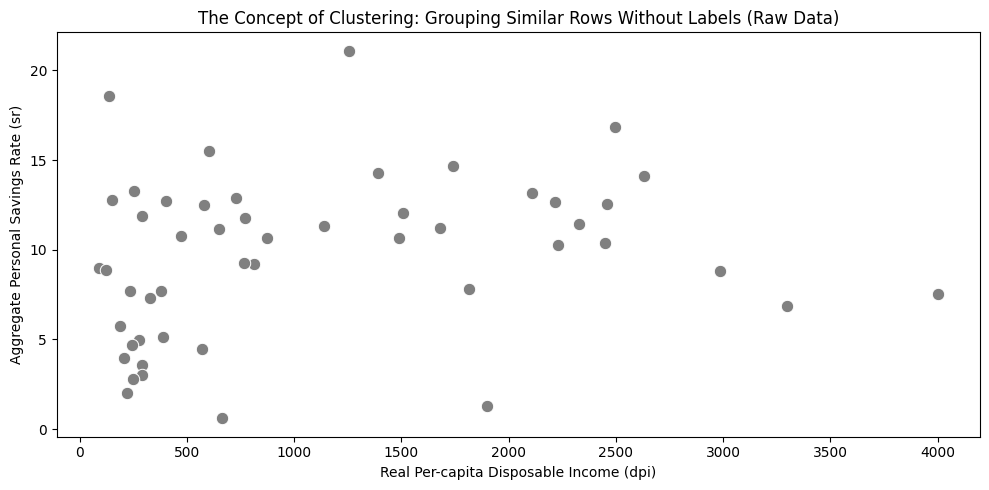

In [17]:
# --- Step 2: Show the Concept of Clustering (Unlabeled Data) ---
plt.figure(figsize=(10, 5))
sns.scatterplot(data=df, x='dpi', y='sr', color='gray', s=80)
plt.title('The Concept of Clustering: Grouping Similar Rows Without Labels (Raw Data)')
plt.xlabel('Real Per-capita Disposable Income (dpi)')
plt.ylabel('Aggregate Personal Savings Rate (sr)')
plt.tight_layout()
plt.show()

In [18]:
# --- Step 3: Standardize the Features ---
# Standardize to avoid features with larger scales (like dpi) dominating the distance calculations
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[features])

In [19]:
# --- Step 4: Hierarchical Clustering (Dendrogram) ---
# Compute linkage and build the tree structure showing relationships
Z = linkage(X_scaled, method='ward')

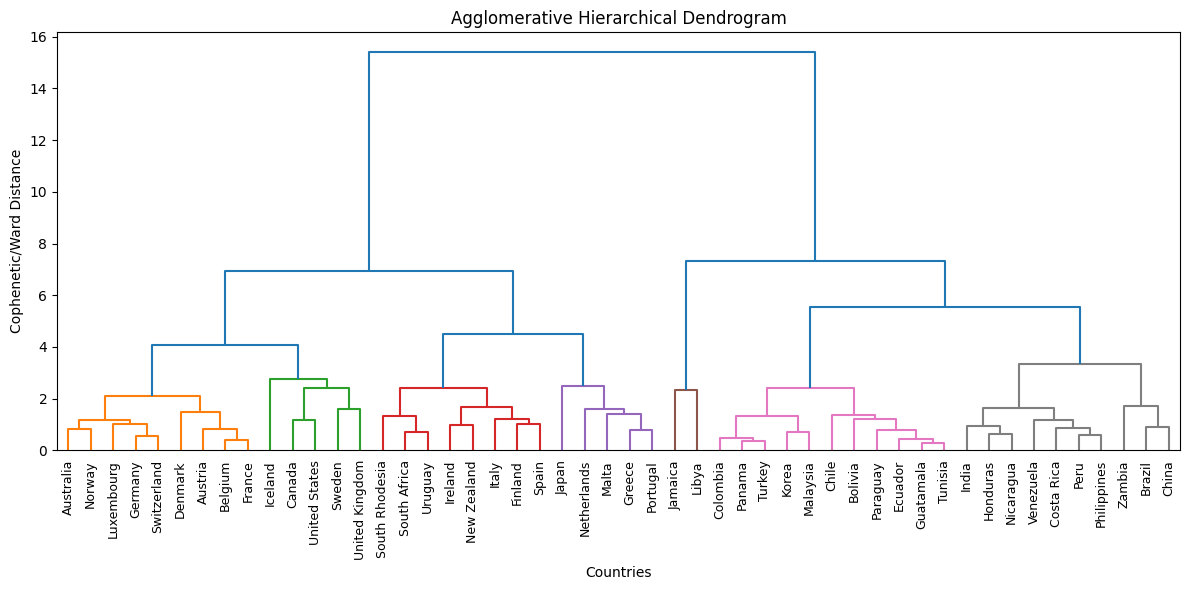

In [20]:
plt.figure(figsize=(12, 6))
plt.title('Agglomerative Hierarchical Dendrogram')
dendrogram(
    Z,
    labels=df['Contry'].values,
    leaf_rotation=90,
    leaf_font_size=9,
    color_threshold=3.5
)
plt.xlabel('Countries')
plt.ylabel('Cophenetic/Ward Distance')
plt.tight_layout()
plt.show()

In [21]:
# --- Step 5: Map Clusters and Plot Final Labeled Scatter Chart ---
# Apply Agglomerative clustering with 3 selected clusters
hc = AgglomerativeClustering(n_clusters=3, metric='euclidean', linkage='ward')
df['Cluster'] = hc.fit_predict(X_scaled).astype(str)

<Axes: xlabel='dpi', ylabel='sr'>

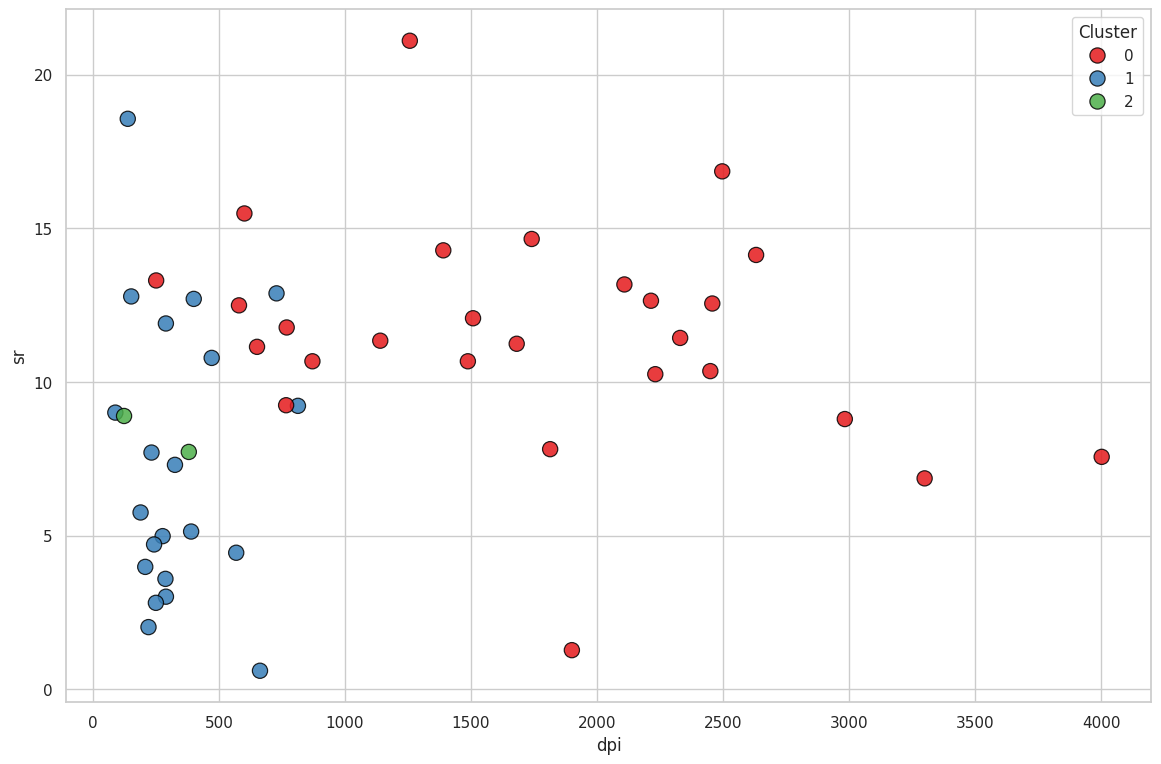

In [22]:

# Plot labeled clusters using Seaborn
plt.figure(figsize=(14, 9))
sns.set_theme(style='whitegrid')

sns.scatterplot(
    data=df,
    x='dpi',
    y='sr',
    hue='Cluster',
    palette='Set1',
    s=120,
    alpha=0.85,
    edgecolor='black'
)

#### Column Population Means:
- sr (Savings Rate): 9.6710
- pop15 (% Population under 15): 35.0896
- pop75 (% Population over 75): 2.2930
- dpi (Per-capita Disposable Income): 1106.7584
- ddpi (Percent growth rate of dpi): 3.7576


### USER PROMPT
You are an expert data science assistant. I need to cluster 50 countries based on their savings behavior data using the following columns: 'sr', 'pop15', 'pop75', 'dpi', and 'ddpi'.

Return a Python script using pandas and scikit-learn that,
1. using StandardScaler ( dpi vs ddpi)
2. Use K-Means clustering algorithm. (like k=3) savings categories.
3. label the cluster
4. scatter plot clusters with 'dpi' (Disposable Income) on the X-axis and 'sr' (Savings Rate) on the Y-axis. Label every point with its country name so I can understand the behavior patterns.

Ensure your code uses matplotlib and gives means.

--------------------------------------------------------------------------------
### AI ASSISTANT RESPONSE



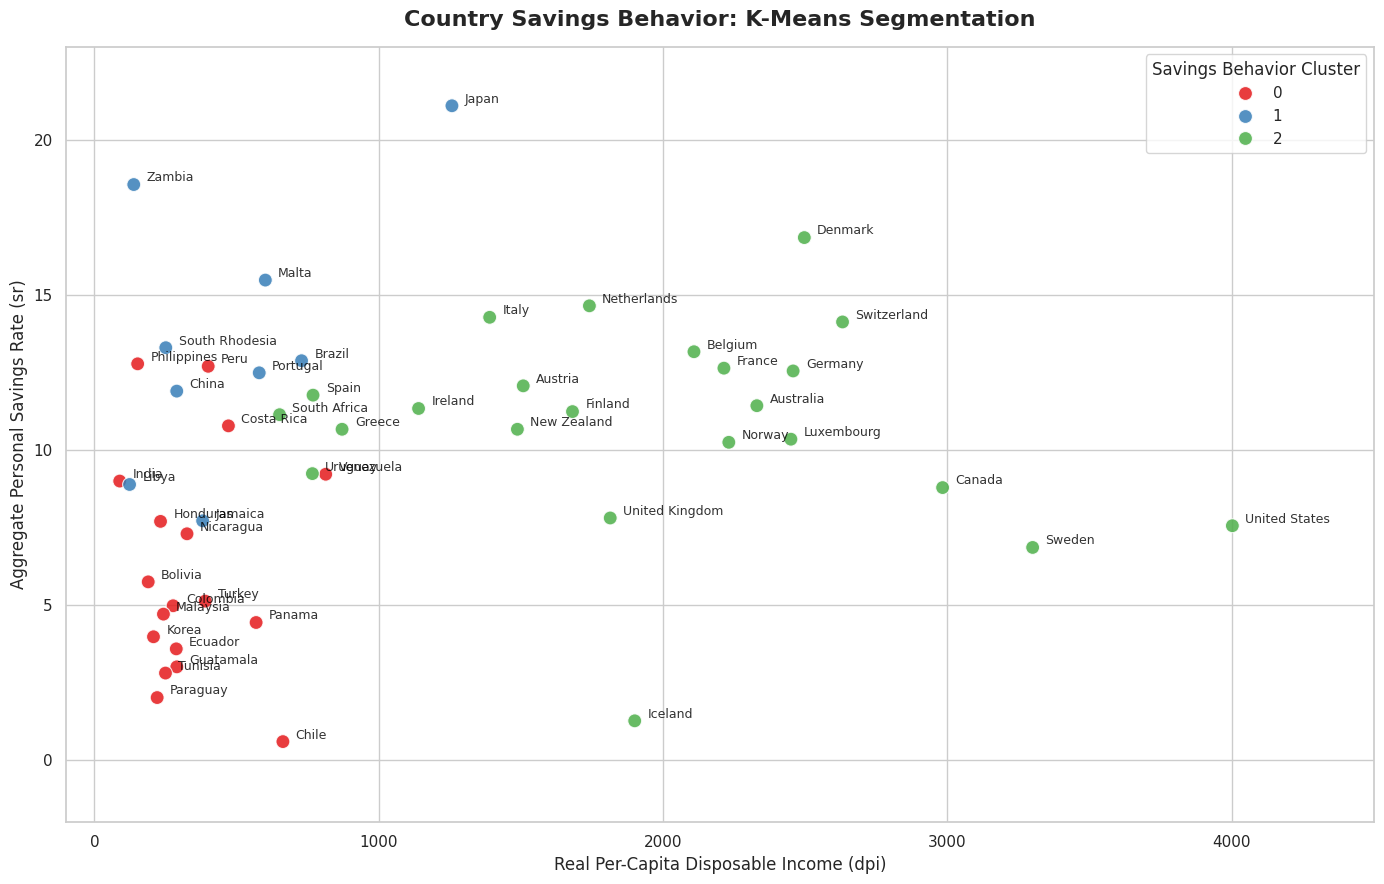

--- Cluster Profiles (Mean Feature Values) ---
            sr  pop15  pop75      dpi  ddpi
Cluster                                    
0         6.14  44.56   1.08   337.15  2.36
1        13.59  37.49   1.62   483.24  7.66
2        10.90  26.74   3.50  1953.04  3.32


In [23]:
import io
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans


# 2. Isolate features and Standardize scales
features = ['sr', 'pop15', 'pop75', 'dpi', 'ddpi']
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[features])

# 3. Fit K-Means Clustering (3 natural group segments)
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['Cluster'] = kmeans.fit_predict(X_scaled)

# 4. Generate the Visualization
plt.figure(figsize=(14, 9))
sns.set_theme(style="whitegrid")

# Create Scatter Plot using 'dpi' and 'sr'
scatter_plot = sns.scatterplot(
    data=df,
    x='dpi',
    y='sr',
    hue='Cluster',
    palette='Set1',
    s=100,
    alpha=0.85,
    edgecolor='w'
)

# Label every data point explicitly with text offset optimization
for idx, row in df.iterrows():
    plt.text(
        x=row['dpi'] + 45,
        y=row['sr'] + 0.1,
        s=row['Contry'],
        fontdict=dict(color='black', alpha=0.8, size=9)
    )

# Formatting chart titles and boundaries
plt.title('Country Savings Behavior: K-Means Segmentation', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Real Per-Capita Disposable Income (dpi)', fontsize=12)
plt.ylabel('Aggregate Personal Savings Rate (sr)', fontsize=12)
plt.xlim(-100, 4500)
plt.ylim(-2, 23)
plt.legend(title='Savings Behavior Cluster', loc='upper right')

plt.tight_layout()
plt.show()

# 5. Display behavioral summaries of our groups
print("--- Cluster Profiles (Mean Feature Values) ---")
print(df.groupby('Cluster')[features].mean().round(2))


Interpretation of Group Results

Running this code returns data into
- High-Income, Aging Demographics, lower % of pop15, and higher pop75. (Cluster A):  **United States, Sweden, and Switzerland** (high dpi values)

- Young Populations (Cluster B): **Bolivia, Colombia, and Zambia** with lower dpi, high pop15 rates, and low personal savings rates (sr).

- High Growth/High Savings Outliers (Cluster C): **Libya** (extreme ddpi) or **Japan** (high savings rates, sr).


### Looking at the overall Means

When looking at the clusters against the overall means, they do differ, For example, the overall average savings rate (`sr`) is **9.67%**, and the average per-capita disposable income (`dpi`) is **\$1,106.76**. Average disposable incomes are \$2,000 to \$4,000, and stable. But, the youth-heavy developing cluster pulls the averages down, showing higher `pop15` metrics than the **35.09%** global mean and weaker personal financial metrics.

---

### Machine Learning Cluster Profiles

The three country clusters are  global macroeconomic and demographic development.

* **Cluster 0** is wealthy,  Western nations with high disposable income, low youth populations, and plentiful aging demographics.
* **Cluster 1** poorer nations struggling with lower income, small elderly populations, and intense economic with youth majorities.
* **Cluster 2** these are high-growth outliers that do not fit economic development.

This data reflect the lifecycle hypothesis of economic savings. Younger populations use resources rather than saving, and mature, high-income employment accumulate wealth. This is shown in the, unsupervised algorithms, and does not need pre-existing labels.

### Unstudied Methods: A Word of Caution

**Caution:** A warning about trusting an AI-generated analysis of a machine learning technique is that you have not studied these concepts and code is highly risky because generative models can comfortably hallucinate statistically normal observations and build entirely meaningless clusters. Unsupervised algorithms like K-Means are sensitive to random skewed data, and will cluster numbers without a reasonable  understanding of the underlying math, you cannot verify whether the AI is explaining appropriate structure or simply returning a random statistical output.
